In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr as count_iqr
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [39]:
df = pd.read_excel("clust_2023.xlsx")
df = df[~df["regions"].isin(["Чукотский автономный округ", "Республика Адыгея", "Республика Тыва"])].set_index("regions")

In [40]:
df_with_clusters_not_scaled = df.copy()

In [41]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)

for i in df.columns:
    df[i] = df_scaled[:, 0] 

df.head()

,x1,x2,x3,x4
regions,,,,
Белгородская область,0.579104,0.579104,0.579104,0.579104
Брянская область,-0.957763,-0.957763,-0.957763,-0.957763
Владимирская область,0.524216,0.524216,0.524216,0.524216
Воронежская область,0.194887,0.194887,0.194887,0.194887
Ивановская область,0.085111,0.085111,0.085111,0.085111


In [42]:
df_with_clusters_scaled = df.copy()

In [43]:
agg_cluster = AgglomerativeClustering(n_clusters=6, linkage='ward')
df_with_clusters_not_scaled["clusters"] = agg_cluster.fit_predict(df)
df_with_clusters_scaled["clusters"] = agg_cluster.fit_predict(df)

In [44]:
df_with_clusters_not_scaled.groupby(by = ["clusters"]).count() 

,x1,x2,x3,x4
clusters,,,,
0,20,20,20,20
1,13,13,13,13
2,8,8,8,8
3,23,23,23,23
4,11,11,11,11
5,4,4,4,4


In [49]:
df_with_clusters[df_with_clusters_not_scaled['clusters'] == 5]

,x1,x2,x3,x4,clusters
regions,,,,,
Московская область,72.5,2.6,184.834,5.5,5
Нижегородская область,72.2,1.9,223.677,7.2,5
Челябинская область,72.5,2.4,131.139,10.0,5
Хабаровский край,72.4,2.1,326.830,9.7,5


<Axes: >

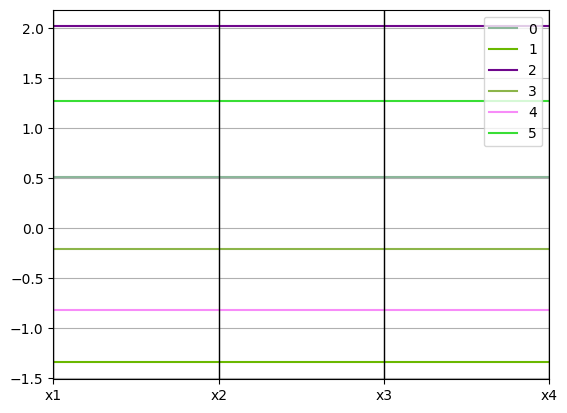

In [46]:
df_with_means = df_with_clusters_scaled.groupby(by = ["clusters"]).mean().reset_index()
pd.plotting.parallel_coordinates(df_with_means, "clusters")

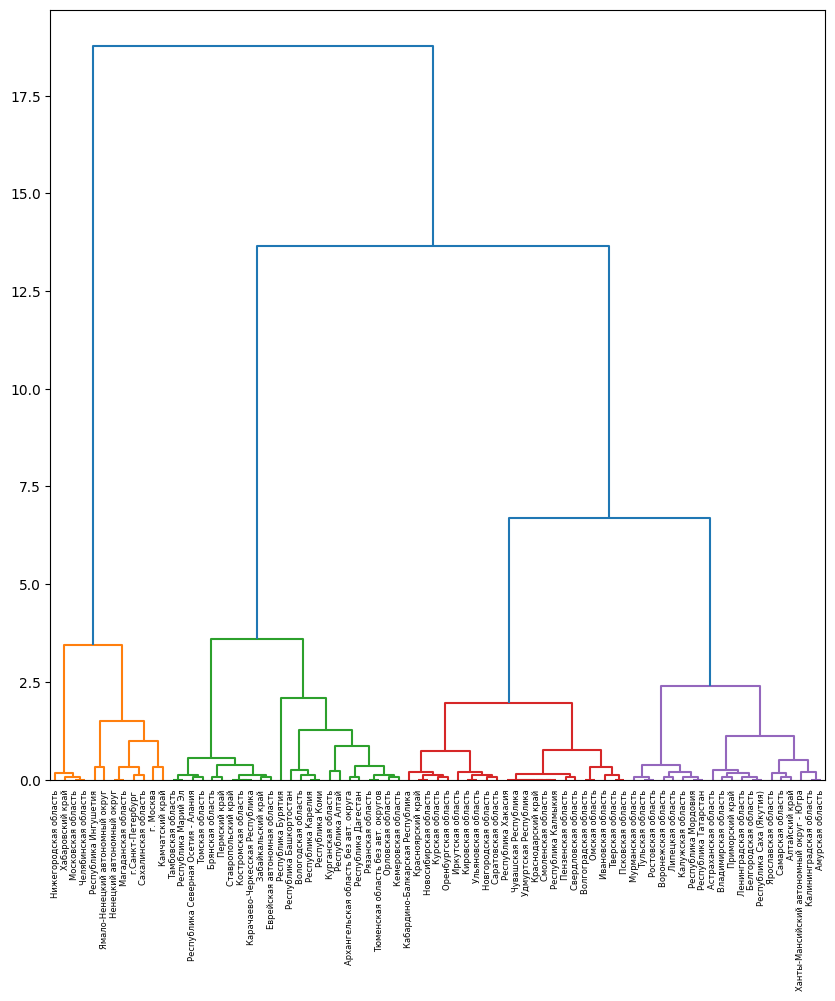

In [47]:
Z = linkage(df, method='ward', metric='euclidean')

fig = plt.figure(figsize=(10, 10))
dn = dendrogram(Z, color_threshold=5, orientation="top", labels = df.index)
plt.show()

In [48]:
df_with_clusters_not_scaled.to_excel("clusters.xlsx")